# V5 training curves

Plots training and validation curves from `training_history_v5.json` and saves paper-ready figures.

**Run order:** run all cells top to bottom. Figures are shown inline *and* saved to the folder printed by the setup cell.

**Note on train vs validation:** the training metrics in the history use fixed 0.5 thresholds with a class-weighted loss, while validation uses the tuned thresholds, so training accuracy / F1 are **not comparable** with validation values and are deliberately not plotted. Only the loss is compared between train and validation.

Requires `matplotlib` (`pip install matplotlib`).

In [3]:
# ---- 1. Setup: edit these two lines if needed ---------------------------------
from pathlib import Path

HISTORY_PATH = Path("../../outputs/gnn_v5/training_history_v5.json")        # e.g. Path("outputs/gnn_v5/training_history_v5.json"); None = auto-search
OUT_DIR = Path("figures")  # relative to the notebook's working directory

# ---- Locate the history file ---------------------------------------------------
CANDIDATES = [
    "outputs/gnn_v5/training_history_v5.json",
    "../outputs/gnn_v5/training_history_v5.json",
    "../../outputs/gnn_v5/training_history_v5.json",
    "training_history_v5.json",
]
if HISTORY_PATH is None:
    HISTORY_PATH = next((Path(c) for c in CANDIDATES if Path(c).exists()), None)
if HISTORY_PATH is None or not Path(HISTORY_PATH).exists():
    raise FileNotFoundError(
        "Could not find training_history_v5.json. Set HISTORY_PATH in this cell. "
        f"Current working directory: {Path.cwd()}"
    )

OUT_DIR = OUT_DIR.resolve()
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Reading history from:", Path(HISTORY_PATH).resolve())
print("Saving figures to   :", OUT_DIR)

Reading history from: /Users/ananyajain/Downloads/project1/deadlockprediction/outputs/gnn_v5/training_history_v5.json
Saving figures to   : /Users/ananyajain/Downloads/project1/deadlockprediction/kernel_deadlock_prototype/experiments/figures


In [4]:
# ---- 2. Imports, style and constants -------------------------------------------
import json

import matplotlib.pyplot as plt

%matplotlib inline

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "legend.fontsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.5,
    "figure.dpi": 150,
})

TRAIN_COLOR = "#1f77b4"
VAL_COLOR = "#d62728"
CLASS_COLORS = {"safe": "#2ca02c", "pre_deadlock": "#ff7f0e", "deadlocked": "#d62728"}
CLASS_LABELS = {"safe": "Safe", "pre_deadlock": "Pre-Deadlock", "deadlocked": "Deadlocked"}
RISK_COLORS = {"risk_50": "#1f77b4", "risk_100": "#9467bd", "risk_300": "#8c564b"}
RISK_LABELS = {"risk_50": "50 ms", "risk_100": "100 ms", "risk_300": "300 ms"}
FIG_SIZE = (3.4, 2.4)  # inches: one column of a two-column paper

In [5]:
# ---- 3. Load the history -------------------------------------------------------
history = json.loads(Path(HISTORY_PATH).read_text())
assert isinstance(history, list) and history, "expected a non-empty list of per-epoch records"

epochs = [e["epoch"] for e in history]
best = max(history, key=lambda e: e["selection_score"])["epoch"]  # checkpoint chosen by validation score
total_s = sum(e["epoch_seconds"] for e in history)

print(f"epochs: {len(history)}   best epoch: {best}   "
      f"total training time: {total_s:,.0f} s ({total_s / 3600:.2f} h)")

epochs: 20   best epoch: 15   total training time: 15,589 s (4.33 h)


In [6]:
# ---- 4. Plot helpers -----------------------------------------------------------
def mark_best(ax):
    ax.axvline(best, color="gray", linestyle="--", linewidth=0.8, label=f"Best epoch ({best})")


def style_epoch_axis(ax):
    ax.set_xlabel("Epoch")
    ax.set_xlim(min(epochs), max(epochs))
    ax.set_xticks([e for e in epochs if e == 1 or e % 5 == 0])


def panel_loss(ax):
    ax.plot(epochs, [e["train"]["loss"] for e in history], color=TRAIN_COLOR,
            marker="o", markersize=2.5, linewidth=1.2, label="Train")
    ax.plot(epochs, [e["validation"]["loss"] for e in history], color=VAL_COLOR,
            marker="s", markersize=2.5, linewidth=1.2, label="Validation")
    ax.set_ylabel("Loss")
    mark_best(ax); style_epoch_axis(ax); ax.legend(loc="best", frameon=False)


def panel_val_metric(ax, key, ylabel):
    ax.plot(epochs, [e["validation"]["metrics"][key] for e in history], color=VAL_COLOR,
            marker="s", markersize=2.5, linewidth=1.2, label="Validation")
    ax.set_ylabel(ylabel)
    mark_best(ax); style_epoch_axis(ax); ax.legend(loc="lower right", frameon=False)


def panel_class_f1(ax):
    for k in ("safe", "pre_deadlock", "deadlocked"):
        ax.plot(epochs, [e["validation"]["metrics"]["per_class"][k]["f1"] for e in history],
                color=CLASS_COLORS[k], marker="o", markersize=2.5, linewidth=1.2, label=CLASS_LABELS[k])
    ax.set_ylabel("Validation F1"); ax.set_ylim(0, 1.0)
    mark_best(ax); style_epoch_axis(ax); ax.legend(loc="lower right", frameon=False)


def panel_risk_f1(ax):
    for k in ("risk_50", "risk_100", "risk_300"):
        ax.plot(epochs, [e["validation"]["risk_metrics"][k]["f1"] for e in history],
                color=RISK_COLORS[k], marker="o", markersize=2.5, linewidth=1.2, label=RISK_LABELS[k])
    ax.set_ylabel("Validation risk F1"); ax.set_ylim(0, 1.0)
    mark_best(ax); style_epoch_axis(ax)
    ax.legend(loc="lower right", frameon=False, title="Horizon", title_fontsize=7)


def panel_selection(ax):
    ax.plot(epochs, [e["selection_score"] for e in history], color="#333333",
            marker="o", markersize=2.5, linewidth=1.2, label="Selection score")
    ax.set_ylabel("Selection score")
    mark_best(ax); style_epoch_axis(ax); ax.legend(loc="lower right", frameon=False)


PANELS = {
    "fig_loss":      ("(a) Loss", panel_loss),
    "fig_accuracy":  ("(b) Validation accuracy", lambda ax: panel_val_metric(ax, "accuracy", "Validation accuracy")),
    "fig_macro_f1":  ("(c) Validation macro-F1", lambda ax: panel_val_metric(ax, "macro_f1", "Validation macro-F1")),
    "fig_class_f1":  ("(d) Per-class validation F1", panel_class_f1),
    "fig_risk_f1":   ("(e) Future-risk heads", panel_risk_f1),
    "fig_selection": ("(f) Checkpoint selection score", panel_selection),
}


def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(OUT_DIR / f"{name}.{ext}", dpi=300, bbox_inches="tight")
    print(f"saved {OUT_DIR / name}.png / .pdf")

## Individual figures (single-column width)

saved /Users/ananyajain/Downloads/project1/deadlockprediction/kernel_deadlock_prototype/experiments/figures/fig_loss.png / .pdf


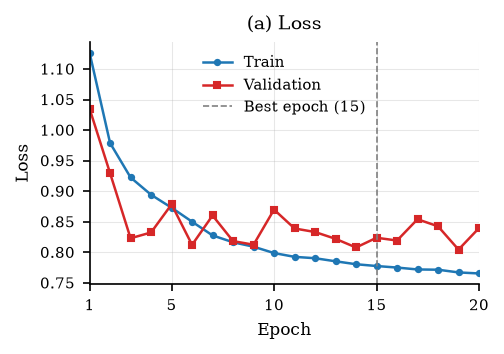

saved /Users/ananyajain/Downloads/project1/deadlockprediction/kernel_deadlock_prototype/experiments/figures/fig_accuracy.png / .pdf


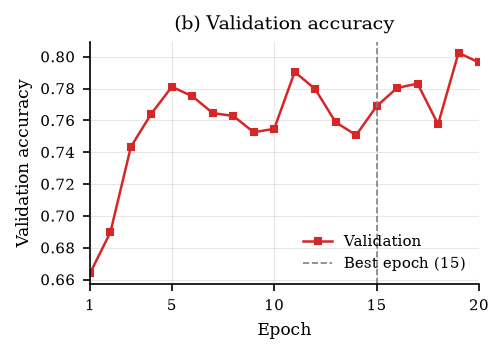

saved /Users/ananyajain/Downloads/project1/deadlockprediction/kernel_deadlock_prototype/experiments/figures/fig_macro_f1.png / .pdf


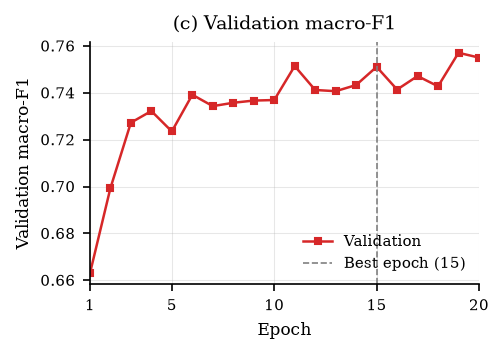

saved /Users/ananyajain/Downloads/project1/deadlockprediction/kernel_deadlock_prototype/experiments/figures/fig_class_f1.png / .pdf


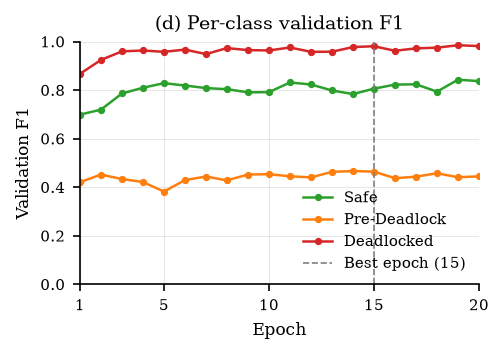

saved /Users/ananyajain/Downloads/project1/deadlockprediction/kernel_deadlock_prototype/experiments/figures/fig_risk_f1.png / .pdf


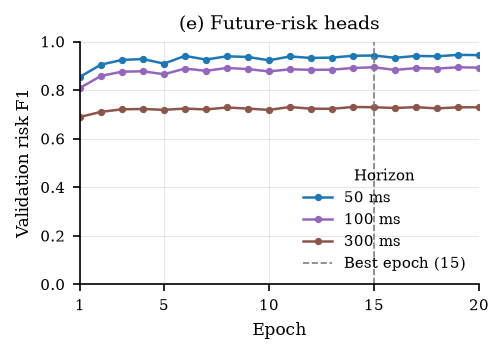

saved /Users/ananyajain/Downloads/project1/deadlockprediction/kernel_deadlock_prototype/experiments/figures/fig_selection.png / .pdf


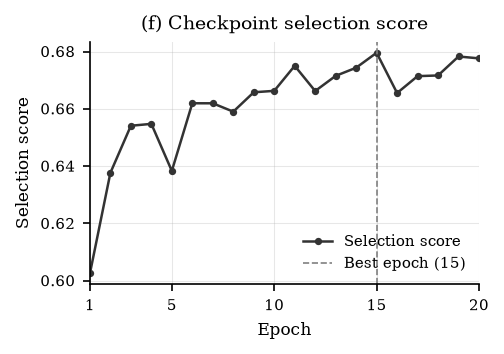

In [7]:
# ---- 5. One figure per panel: shown inline and saved ---------------------------
for name, (title, draw) in PANELS.items():
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    draw(ax)
    ax.set_title(title)
    fig.tight_layout()
    save(fig, name)
    plt.show()

## Combined overview (2 x 3 panel)

saved /Users/ananyajain/Downloads/project1/deadlockprediction/kernel_deadlock_prototype/experiments/figures/fig_training_overview.png / .pdf


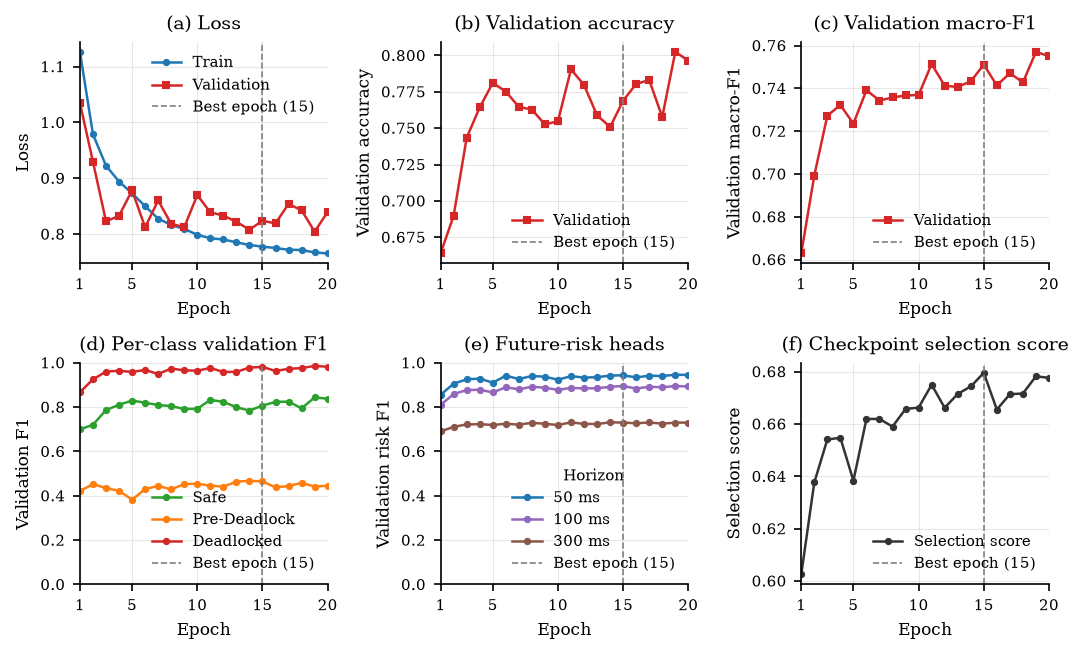

In [8]:
# ---- 6. Combined overview figure -----------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.4))
for ax, (name, (title, draw)) in zip(axes.flat, PANELS.items()):
    draw(ax)
    ax.set_title(title)
fig.tight_layout()
save(fig, "fig_training_overview")
plt.show()

In [9]:
# ---- 7. Summary ----------------------------------------------------------------
print(f"Figures written to: {OUT_DIR}")
for p in sorted(OUT_DIR.glob("fig_*")):
    print(" ", p.name)

Figures written to: /Users/ananyajain/Downloads/project1/deadlockprediction/kernel_deadlock_prototype/experiments/figures
  fig_accuracy.pdf
  fig_accuracy.png
  fig_class_f1.pdf
  fig_class_f1.png
  fig_loss.pdf
  fig_loss.png
  fig_macro_f1.pdf
  fig_macro_f1.png
  fig_risk_f1.pdf
  fig_risk_f1.png
  fig_selection.pdf
  fig_selection.png
  fig_training_overview.pdf
  fig_training_overview.png
